In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("Mall_Customers.csv")
print(df.shape)
display(df.head())
df.info()
print(df.isnull().sum())
display(df.describe())

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [2]:
df = df.rename(columns={"Genre": "Gender",
                        "Annual Income (k$)": "Income",
                        "Spending Score (1-100)": "Spending"})
df = df.drop(columns=["CustomerID"])
df.head()

,Gender,Age,Income,Spending
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


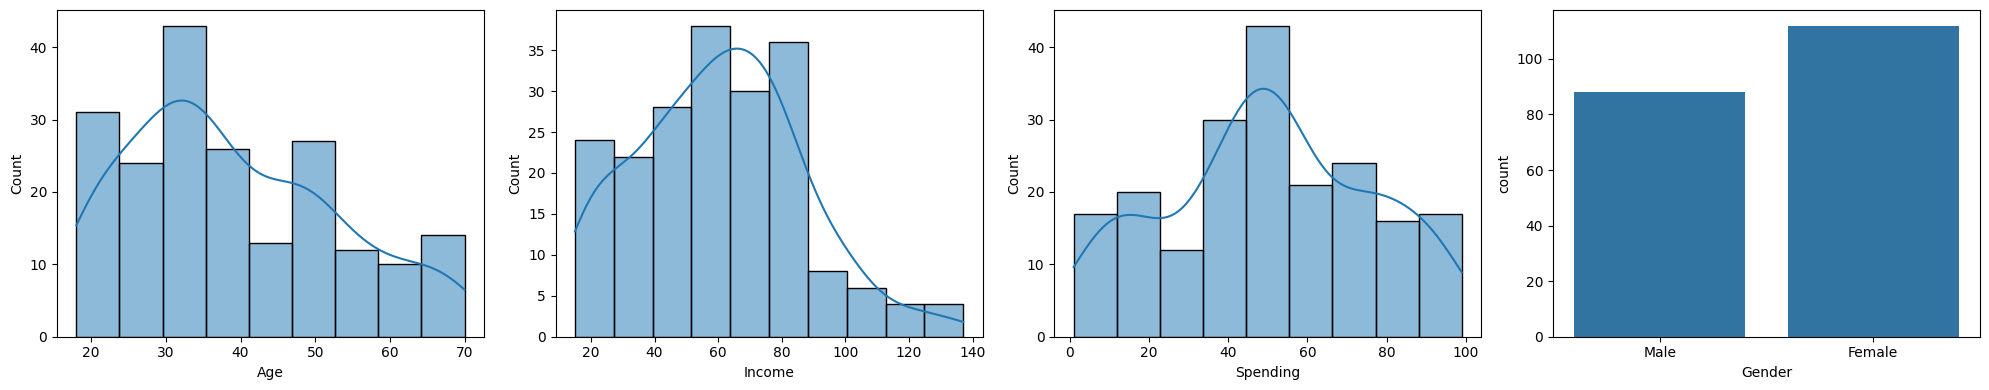

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
sns.histplot(df["Age"], kde=True, ax=ax[0])
sns.histplot(df["Income"], kde=True, ax=ax[1])
sns.histplot(df["Spending"], kde=True, ax=ax[2])
sns.countplot(x="Gender", data=df, ax=ax[3])
plt.tight_layout(); plt.show()

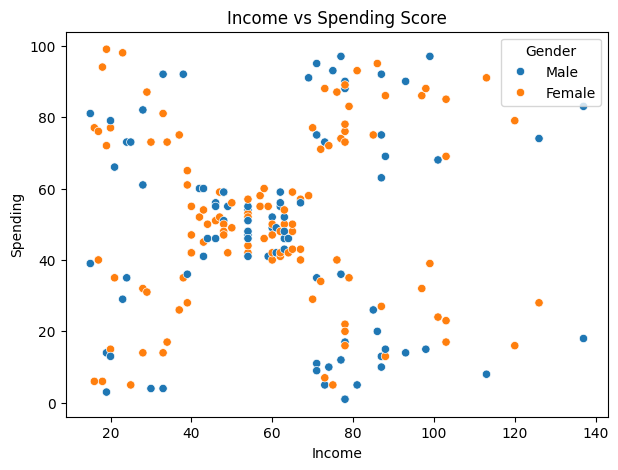

In [4]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x="Income", y="Spending", hue="Gender", data=df)
plt.title("Income vs Spending Score"); plt.show()

In [5]:
from sklearn.preprocessing import StandardScaler

X = df[["Income", "Spending"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


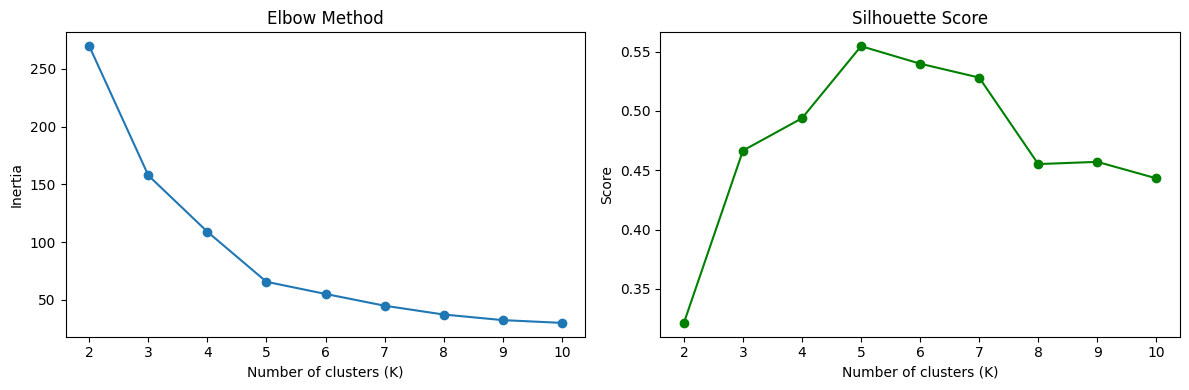

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia, sil = [], []
K = range(2, 11)
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, inertia, marker="o"); ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters (K)"); ax[0].set_ylabel("Inertia")
ax[1].plot(K, sil, marker="o", color="green"); ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters (K)"); ax[1].set_ylabel("Score")
plt.tight_layout(); plt.show()

In [7]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("Silhouette:", silhouette_score(X_scaled, df["Cluster"]))
print(df["Cluster"].value_counts().sort_index())
df.head()

Silhouette: 0.5546571631111091
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


,Gender,Age,Income,Spending,Cluster
0,Male,19,15,39,4
1,Male,21,15,81,2
2,Female,20,16,6,4
3,Female,23,16,77,2
4,Female,31,17,40,4


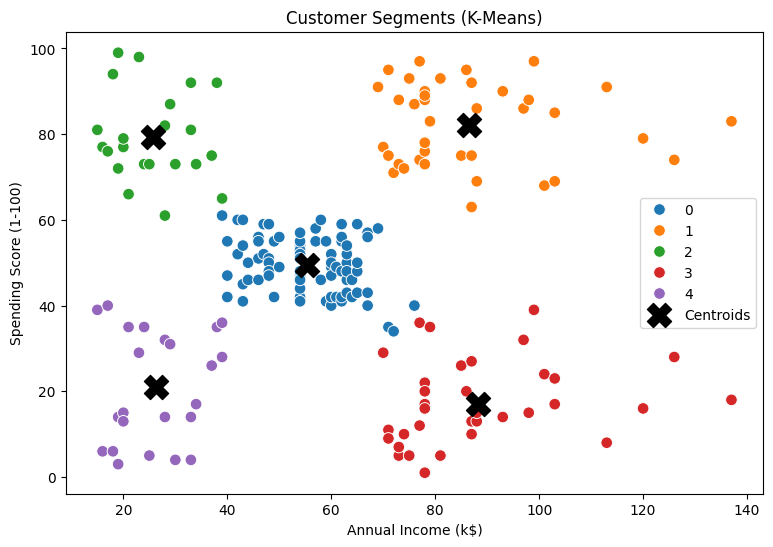

In [8]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
sns.scatterplot(x="Income", y="Spending", hue="Cluster",
                palette="tab10", data=df, s=70)
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c="black",
            marker="X", label="Centroids")
plt.title("Customer Segments (K-Means)")
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score (1-100)")
plt.legend(); plt.show()

In [9]:
profile = df.groupby("Cluster").agg(
    Customers=("Income", "size"),
    Avg_Age=("Age", "mean"),
    Avg_Income=("Income", "mean"),
    Avg_Spending=("Spending", "mean"),
    Male_Percent=("Gender", lambda s: (s == "Male").mean() * 100)
).round(1)
profile

,Customers,Avg_Age,Avg_Income,Avg_Spending,Male_Percent
Cluster,,,,,
0,81,42.7,55.3,49.5,40.7
1,39,32.7,86.5,82.1,46.2
2,22,25.3,25.7,79.4,40.9
3,35,41.1,88.2,17.1,54.3
4,23,45.2,26.3,20.9,39.1


In [10]:
X2 = StandardScaler().fit_transform(df[["Age", "Income", "Spending"]])
km2 = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X2)
print("Silhouette (3 features):", silhouette_score(X2, km2.labels_))

Silhouette (3 features): 0.41664341513732767
